# Fault classification on the TEP: GCN vs FFNN
Each window of plant data (30 rows x 33 variables: `xmeas_1-22` and `xmv_1-11`) is classified into one of 6 classes (normal + faults 1, 4, 8, 13, 14).

| Case | Model                            |
|---|----------------------------------|
| **Case 1** | GNN (3 layers, hidden width 128) |
| **Case 2** | FFNN                             |



In [22]:
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.nn import GCNConv
from sklearn.metrics import confusion_matrix, recall_score
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 1. Set up
Builds the graph and loads datasets. Configuration and methods are found in helper scripts

Data: ex1_data_processing
- Loads selected number of runs of chosen fault labels
- Auto scales and windows data
- Returns a dictionary of windows that can be sliced for input into the GNN

Graph: ex1_graph_helper
- Builds the graph from the provided adjacency list and visualises the graph

In [23]:
# Get data
from ex1_data_processing import get_windows, CLASSES, N_NODES
sets = get_windows()

def to_tensors(ds):
    Xw, y = ds.batch(np.arange(len(ds)))        # already (B, 33, 30)
    return torch.from_numpy(Xw), torch.from_numpy(y)

Xtr, ytr = to_tensors(sets["train"])
Xva, yva = to_tensors(sets["val"])
Xte, yte = to_tensors(sets["test"])
print("train", tuple(Xtr.shape), " val", tuple(Xva.shape), " test", tuple(Xte.shape))

train (13900, 33, 30)  val (2780, 33, 30)  test (27700, 33, 30)


graph: 33 nodes, 88 directed edges


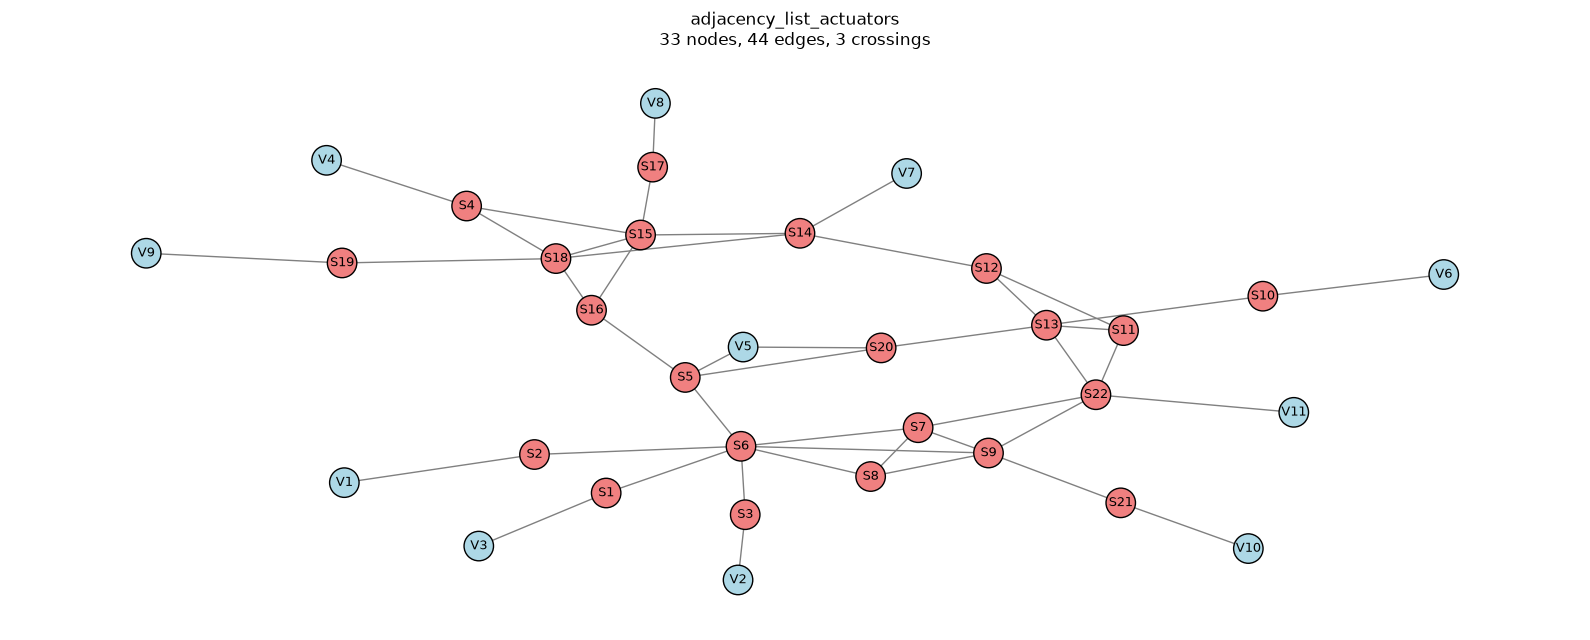

In [24]:
# Get graph
from ex1_graph_helper import get_edge_index
node_ids = [i for i in range(1, 34)]
sensor_names = [f"S{i}" for i in range(1,23)]
valve_names = [f"V{i}" for i in range(1,20)]
node_names = dict(zip(node_ids, sensor_names + valve_names))

adjacency_list = [
    # feeds + recycle -> reactor feed flow
    (1,6),(2,6),(3,6),(5,6),
    # stripper overhead (stream 5, S16) merges into recycle header at S5
    (16,5),
    # C feed -> stripper (level, temperature)
    (4,15),(4,18),
    # reactor feed -> reactor, reactor internals, cooling jacket
    (6,7),(6,8),(6,9),(7,8),(7,9),(8,9),(9,21),
    # reactor -> condenser -> separator
    (7,22),(9,22),(22,11),(22,13),
    # separator internals
    (11,12),(11,13),(12,13),
    # separator vapour -> compressor / purge, compressor -> recycle flow
    (13,20),(13,10),(20,5),
    # separator liquid -> underflow -> stripper
    (12,14),(14,15),(14,18),
    # stripper internals, product, steam
    (15,16),(15,18),(16,18),(15,17),(18,19),

    # actuators (valve -> sensor on the same line)
    (23,2),(24,3),(25,1),(26,4),   # V1 D, V2 E, V3 A, V4 C feed valves
    (27,5),(27,20),                # V5 compressor recycle
    (28,10),                       # V6 purge
    (29,14),                       # V7 separator underflow
    (30,17),                       # V8 product
    (31,19),                       # V9 steam
    (32,21),                       # V10 reactor CW
    (33,22),                       # V11 condenser CW
]

# The GCN (i.e. GNN) library of Pytorch takes in a graph as a list of its edges, not as the adjacency matrix A-hat as written in the report
# But both are just ways to represent the graph
edge_index = get_edge_index(adjacency_list, node_names=node_names, plot=True)             # plots

### 2. Configuration + Shared training / evaluation code

In [25]:
# ---- config: edit these --------
EPOCHS, BS, LR = 40, 256, 1e-3
N_CLASSES = len(CLASSES)
results = {}                # case name -> dict(hist, pred, val_acc, test_acc, params, layers)
N_LAYERS = 3                # number of GCNConv layers (= message-passing hops)
HIDDEN_GNN = 128            # GNN hidden width
HIDDEN_FFNN = (36, 18)     # Architecture of FNN model. E.g. (256, 128) -> 2 layers: 256 nodes then 128
# ---------------------------------

In [26]:
@torch.no_grad()
def predict(model, X, bs=2048):
    model.eval()
    return torch.cat([model(X[i:i+bs].to(device)).argmax(1).cpu() for i in range(0, len(X), bs)])

def run_case(name, model, n_nodes, seed=0):
    # Train `model` on the first n_nodes node-rows of every window; keep the best epoch on val.
    torch.manual_seed(seed)
    model = model.to(device)
    Xt, Xv, Xs = Xtr[:, :n_nodes], Xva[:, :n_nodes], Xte[:, :n_nodes]
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    hist = {"loss": [], "val_acc": []}
    best_acc, best_state = -1, None
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(Xt))
        tot = 0.0
        for i in range(0, len(perm), BS):
            idx = perm[i:i+BS]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xt[idx].to(device)), ytr[idx].to(device))
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        va = (predict(model, Xv) == yva).float().mean().item()
        hist["loss"].append(tot / len(perm)); hist["val_acc"].append(va)
        if va > best_acc:
            best_acc, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"[{name}] epoch {ep+1:2d}  loss {hist['loss'][-1]:.4f}  val acc {va:.4f}")
    model.load_state_dict(best_state)
    pred = predict(model, Xs).numpy()
    res = dict(hist=hist, pred=pred, val_acc=best_acc, test_acc=(pred == yte.numpy()).mean(),
               params=sum(p.numel() for p in model.parameters()))
    print(f"[{name}] best val acc {best_acc:.4f}   test acc {res['test_acc']:.4f}   params {res['params']:,}")
    return res

### 3. Model Training and Inference

##### Case 1: GNN
* 33 Nodes: 22 sensors (`xmeas_1-22`) + 11 actuators (`xmv_1-11`) connected as per Figure 7
* Depth = 3 <=> 3 GNN layers <=> 3 hops of message passing
* Hidden width = 128.

In [27]:
class GCNClassifier(nn.Module):
    # n_layers x GCNConv (each layer = one hop) + mean pool over nodes + linear head. Input (B, N, F), fixed graph.
    def __init__(self, edge_index, in_dim, hidden=64, n_layers=2, p=0.2):
        super().__init__()
        self.register_buffer("edge_index", edge_index)
        dims = [in_dim] + [hidden] * n_layers
        self.convs = nn.ModuleList(GCNConv(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.drop = nn.Dropout(p)
        self.head = nn.Linear(hidden, N_CLASSES)

    def forward(self, x):
        h = x
        for i, conv in enumerate(self.convs):
            h = F.relu(conv(h, self.edge_index))
            if i < len(self.convs) - 1:
                h = self.drop(h)
        return self.head(h.mean(dim=1))

model = GCNClassifier(edge_index, in_dim=Xtr.shape[-1], hidden=HIDDEN_GNN, n_layers=N_LAYERS)
results["Case 1: GCN"] = run_case("Case 1: GCN", model, n_nodes=N_NODES)

[Case 1: GCN] epoch  1  loss 1.2504  val acc 0.7565
[Case 1: GCN] epoch  5  loss 0.5538  val acc 0.7903
[Case 1: GCN] epoch 10  loss 0.4656  val acc 0.8403
[Case 1: GCN] epoch 15  loss 0.4145  val acc 0.8187
[Case 1: GCN] epoch 20  loss 0.3740  val acc 0.8414
[Case 1: GCN] epoch 25  loss 0.3409  val acc 0.8730
[Case 1: GCN] epoch 30  loss 0.3194  val acc 0.8781
[Case 1: GCN] epoch 35  loss 0.3042  val acc 0.8914
[Case 1: GCN] epoch 40  loss 0.2803  val acc 0.8867
[Case 1: GCN] best val acc 0.9047   test acc 0.9193   params 37,766


##### Case 2: FFNN
- Densely connected multilayer perceptron (MLP) with layers of 256-128-6 nodes

In [28]:
class FFNN(nn.Module):
    # MLP on the flattened window (33 x 30 = 990 inputs).
    def __init__(self, in_dim, hidden=HIDDEN_FFNN, p=0.2):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p)]
            d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, N_CLASSES))

    def forward(self, x):
        return self.net(x.flatten(1))

results["Case 2: FFNN"] = run_case("Case 2: FFNN", FFNN(in_dim=N_NODES * Xtr.shape[-1]), n_nodes=N_NODES)

[Case 2: FFNN] epoch  1  loss 0.8998  val acc 0.8712
[Case 2: FFNN] epoch  5  loss 0.1759  val acc 0.9827
[Case 2: FFNN] epoch 10  loss 0.1105  val acc 0.9885
[Case 2: FFNN] epoch 15  loss 0.0749  val acc 0.9881
[Case 2: FFNN] epoch 20  loss 0.0684  val acc 0.9899
[Case 2: FFNN] epoch 25  loss 0.0645  val acc 0.9860
[Case 2: FFNN] epoch 30  loss 0.0493  val acc 0.9896
[Case 2: FFNN] epoch 35  loss 0.0465  val acc 0.9914
[Case 2: FFNN] epoch 40  loss 0.0426  val acc 0.9903
[Case 2: FFNN] best val acc 0.9921   test acc 0.9918   params 36,456


### 4. Results Analysis
- Comparison of results from both models

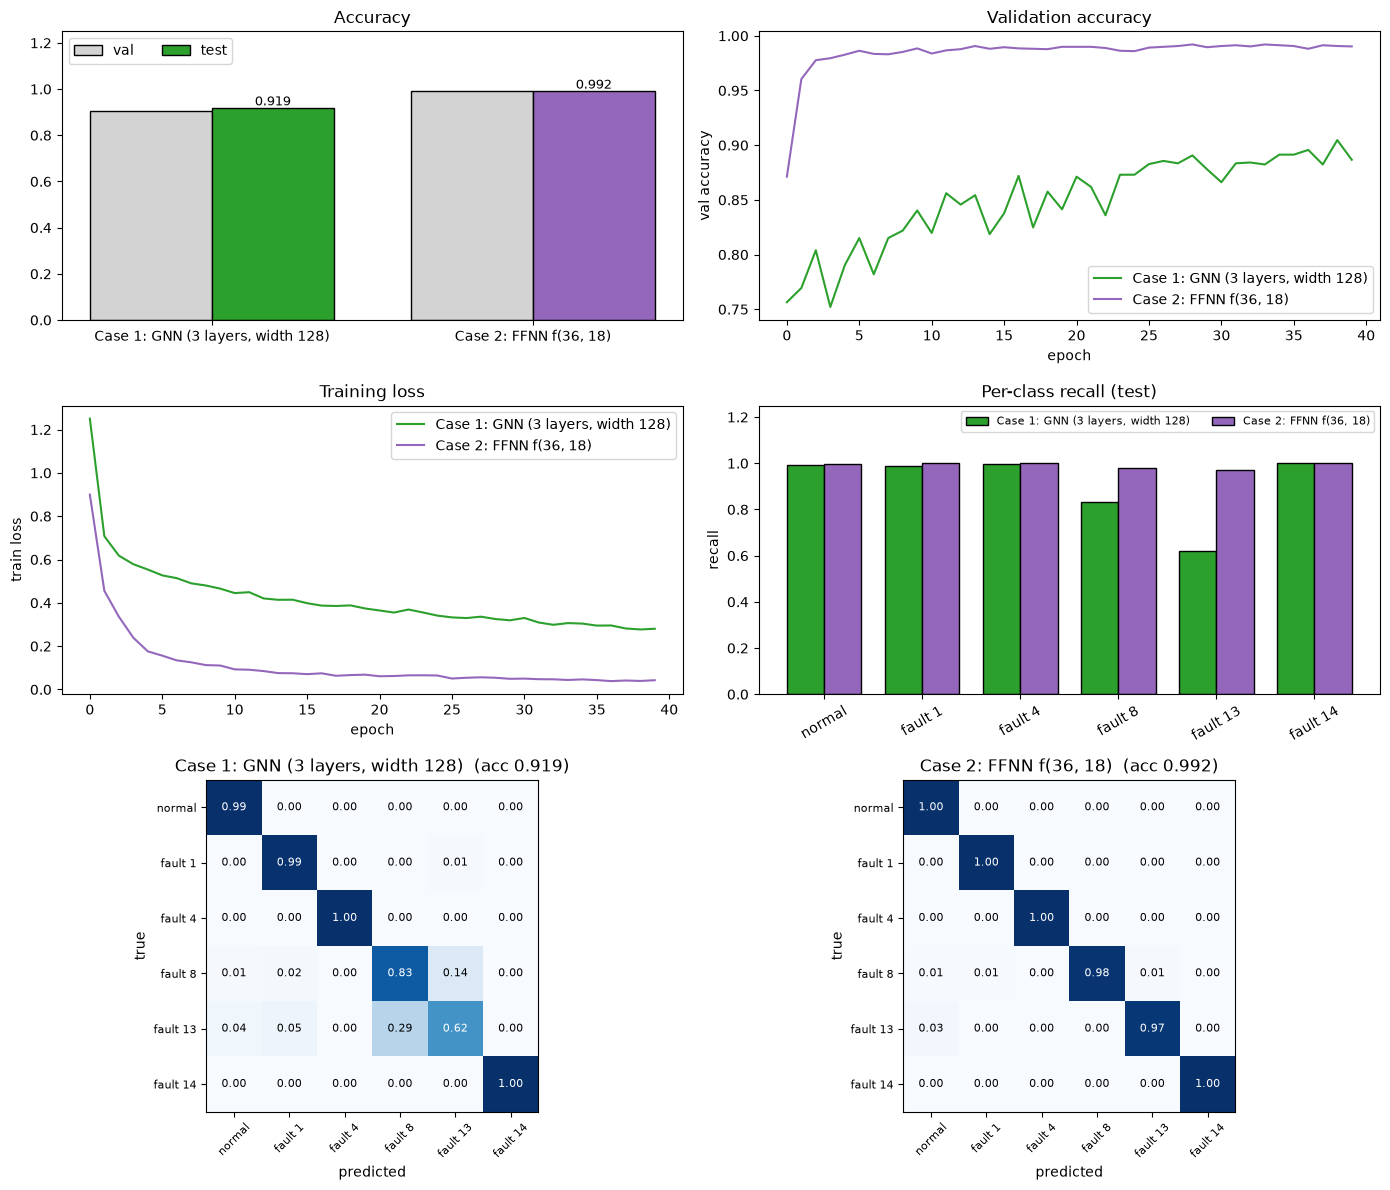

case                             params  val acc  test acc
Case 1: GCN                      37,766   0.9047    0.9193
Case 2: FFNN                     36,456   0.9921    0.9918


In [29]:
plt.style.use("default")                                  # reset any dark-theme colours: black text/axes on white
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "axes.edgecolor": "black",
                     "xtick.color": "black", "ytick.color": "black", "axes.facecolor": "white",
                     "figure.facecolor": "white", "savefig.facecolor": "white"})

names = list(results)
short = [f"Case 1: GNN ({N_LAYERS} layers, width {HIDDEN_GNN})", f"Case 2: FFNN f{HIDDEN_FFNN}"]
cls_names = [("normal" if c == 0 else f"fault {c}") for c in CLASSES]
true = yte.numpy()
colors = ["tab:green", "tab:purple"]
K = len(names)

fig = plt.figure(figsize=(14, 12), facecolor="white")
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15])

# (a) accuracy
ax = fig.add_subplot(gs[0, 0])
x = np.arange(K); w = 0.38
ax.bar(x - w/2, [results[n]["val_acc"] for n in names], w, label="val", color="lightgray", edgecolor="k")
ax.bar(x + w/2, [results[n]["test_acc"] for n in names], w, label="test", color=colors, edgecolor="k")
for xi, n in zip(x, names):
    ax.text(xi + w/2, results[n]["test_acc"] + 0.01, f"{results[n]['test_acc']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylim(0, 1.25); ax.set_title("Accuracy"); ax.legend(loc="upper left", ncol=2)

# (b) validation accuracy curves
ax = fig.add_subplot(gs[0, 1])
for n, c, s in zip(names, colors, short):
    ax.plot(results[n]["hist"]["val_acc"], color=c, label=s)
ax.set_xlabel("epoch"); ax.set_ylabel("val accuracy"); ax.set_title("Validation accuracy"); ax.legend()

# (c) training loss
ax = fig.add_subplot(gs[1, 0])
for n, c, s in zip(names, colors, short):
    ax.plot(results[n]["hist"]["loss"], color=c, label=s)
ax.set_xlabel("epoch"); ax.set_ylabel("train loss"); ax.set_title("Training loss"); ax.legend()

# (d) per-class recall
ax = fig.add_subplot(gs[1, 1])
recalls = [recall_score(true, results[n]["pred"], average=None, labels=range(N_CLASSES)) for n in names]
w = 0.38
for k, (r, c, s) in enumerate(zip(recalls, colors, short)):
    ax.bar(np.arange(N_CLASSES) + (k - 0.5) * w, r, w, color=c, label=s, edgecolor="k")
ax.set_xticks(np.arange(N_CLASSES)); ax.set_xticklabels(cls_names, rotation=30)
ax.set_ylim(0, 1.25); ax.set_ylabel("recall"); ax.set_title("Per-class recall (test)"); ax.legend(ncol=2, fontsize=8)

# (e) confusion matrices
for j, (n, s) in enumerate(zip(names, short)):
    ax = fig.add_subplot(gs[2, j])
    cm = confusion_matrix(true, results[n]["pred"], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for r in range(N_CLASSES):
        for c in range(N_CLASSES):
            ax.text(c, r, f"{cm[r, c]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[r, c] > .5 else "black")
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(cls_names, rotation=45, fontsize=8)
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(cls_names, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{s}  (acc {results[n]['test_acc']:.3f})")
plt.tight_layout()
fig.savefig("results.png", dpi=200, facecolor="white", bbox_inches="tight")   # white-background PNG; save before show()
plt.show()

print(f"{'case':28s} {'params':>10s} {'val acc':>8s} {'test acc':>9s}")
for n in names:
    print(f"{n:28s} {results[n]['params']:>10,} {results[n]['val_acc']:>8.4f} {results[n]['test_acc']:>9.4f}")